# Case Study 6: Comparative Analysis of Classification Algorithms for Bank Marketing Prediction

| | |
|---|---|
| **Subject** | Fundamentals of Data Science |
| **Name** | Nikhil Kotte |
| **Roll No** | 160124733191 |
| **Section** | CSE-3 |
| **Year** | III Year, V Semester (2026-27) |
| **Faculty** | <FACULTY NAME> |
| **College** | Chaitanya Bharathi Institute of Technology (CBIT), Hyderabad |

## Objective

A Portuguese bank runs telephone campaigns to sell term deposits. Using its historical campaign records, I build and compare four classifiers (Logistic Regression, Decision Tree, K-Nearest Neighbours and Random Forest) that predict whether a customer will subscribe (`y = yes`) **before** the call is made. The models are compared with accuracy, precision, recall, F1-score, ROC-AUC and confusion matrices, and the best model is chosen by looking at what missed subscribers and wasted calls mean for the bank, not by accuracy alone.

The notebook follows the brief: Task 1 Data Understanding and Preprocessing, Task 2 Exploratory Data Analysis, Task 3 Model Development, Task 4 Comparison and Visualisation, Task 5 Interpretation and Business Recommendations.

**Purpose:** Import the libraries, fix the random seed, create the `figures/` and `results/` folders and define a helper that saves every figure before showing it.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

RANDOM_STATE = 42
FIG_DIR, RES_DIR = Path("figures"), Path("results")
for d in (FIG_DIR, RES_DIR):
    d.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)


def save_fig(name):
    """Tidy the layout, save the current figure to figures/ and display it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150)
    plt.show()


print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.1.0 | scikit-learn 1.9.1


**Observation:** All libraries loaded without errors (pandas 3.1.0, scikit-learn 1.9.1). The same versions are pinned in `requirements.txt`.

## Task 1: Data Understanding and Preprocessing

### 1.1 Choice of data file

The UCI Bank Marketing download contains two versions. I use `bank-additional/bank-additional-full.csv` (41,188 rows, May 2008 to November 2010) instead of the older `bank/bank-full.csv` because it is the newer UCI version and it adds five **social and economic context attributes** (employment variation rate, consumer price index, consumer confidence index, Euribor 3 month rate and number of employees). The dataset authors report that these attributes noticeably improve prediction even without the call duration, which suits a realistic pre-call model. The file uses `;` as the delimiter.

**Purpose:** Load the CSV with the semicolon separator and show the first 10 records and the dimensions.

In [2]:
DATA_PATH = Path("bank+marketing/bank-additional/bank-additional/bank-additional-full.csv")
df = pd.read_csv(DATA_PATH, sep=";")
print("Shape (rows, columns):", df.shape)
df.head(10)

Shape (rows, columns): (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,198,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,59,admin.,married,professional.course,no,no,no,telephone,may,mon,139,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
7,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,217,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
8,24,technician,single,professional.course,no,yes,no,telephone,may,mon,380,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
9,25,services,single,high.school,no,yes,no,telephone,may,mon,50,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


**Observation:** The file loaded correctly with `sep=';'`: **41,188 rows and 21 columns** (20 inputs plus the target `y`). The first 10 rows are all May calls by telephone with `pdays = 999` and `poutcome = nonexistent`, and the economic indicators are identical across them because they describe the same period. This confirms the file is ordered by date, which is why a random stratified split is needed rather than taking the first rows.

**Purpose:** Check the data type of every column.

In [3]:
df.dtypes.to_frame("dtype").T

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
dtype,int64,str,str,str,str,str,str,str,str,str,int64,int64,int64,int64,str,float64,float64,float64,float64,float64,str


**Observation:** Five columns are integers (age, duration, campaign, pdays, previous), five are floats (the social and economic indicators) and the remaining eleven, including the target `y`, are text (`str`).

**Purpose:** Compute descriptive statistics for the numeric columns and for the categorical columns, and save the numeric table for the report.

In [4]:
num_desc = df.describe().T.round(3)
num_desc.to_csv(RES_DIR / "summary_stats_numeric.csv")
num_desc

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024,10.421,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285,259.279,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.568,2.770,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475,186.911,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.173,0.495,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.082,1.571,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.576,0.579,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.503,4.628,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621,1.734,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.036,72.252,4963.600,5099.100,5191.000,5228.100,5228.100


**Observation:** * **age**: 17 to 98 years, median 38.
* **duration**: median 180 seconds but up to 4,918, very skewed (excluded from models, see 1.7).
* **campaign**: median 2 calls, but up to 56 calls for one customer in this campaign.
* **pdays**: the 25th, 50th and 75th percentiles are all 999, so most customers were never contacted before.
* **previous**: 0 for at least 75% of customers.
* **euribor3m** ranges from 0.634 to 5.045 and **emp.var.rate** from -3.4 to 1.4, showing that the data covers very different economic conditions (before and during the 2008 to 2010 crisis).

In [5]:
df.select_dtypes(exclude="number").describe().T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


**Observation:** There are 12 job types (most common: admin., 10,422), 4 marital statuses (married, 24,928) and 8 education levels (university.degree, 12,168). May is by far the busiest month (13,769 calls), cellular is the most common contact type (26,144) and `poutcome` is 'nonexistent' for 35,563 customers. The target is 'no' for 36,548 rows, so the data is clearly imbalanced.

### 1.2 Numerical, categorical and target attributes

**Purpose:** Split the columns into numerical attributes, categorical attributes and the target, using the data types and the UCI attribute description.

In [6]:
TARGET = "y"
numerical_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = [c for c in df.select_dtypes(exclude="number").columns if c != TARGET]
print(f"Numerical attributes ({len(numerical_cols)}):", numerical_cols)
print(f"Categorical attributes ({len(categorical_cols)}):", categorical_cols)
print("Target attribute:", TARGET, "->", df[TARGET].unique().tolist())

Numerical attributes (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical attributes (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Target attribute: y -> ['no', 'yes']


**Observation:** There are **10 numerical attributes** (age, duration, campaign, pdays, previous and the five economic indicators), **10 categorical attributes** (job, marital, education, default, housing, loan, contact, month, day_of_week, poutcome) and the **binary target `y`** with values 'no' and 'yes'.

### 1.3 Missing and 'unknown' entries

**Purpose:** Check for real missing values (NaN) and count the 'unknown' label in every categorical column, since the dataset codes missing categorical information as 'unknown'.

In [7]:
print("Total NaN values in the whole dataset:", int(df.isna().sum().sum()))
unknown = pd.DataFrame({
    "unknown_count": [(df[c] == "unknown").sum() for c in categorical_cols],
    "unknown_pct": [round((df[c] == "unknown").mean() * 100, 2) for c in categorical_cols],
}, index=categorical_cols).sort_values("unknown_count", ascending=False)
unknown.to_csv(RES_DIR / "unknown_counts.csv")
unknown

Total NaN values in the whole dataset: 0


,unknown_count,unknown_pct
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19
contact,0,0.00
month,0,0.00
day_of_week,0,0.00
poutcome,0,0.00


**Observation:** There are **no NaN values**, but missing information is coded as 'unknown' in six categorical columns. **default has the most (8,597 rows, 20.87%)**, followed by education (1,731, 4.20%), housing and loan (990 each, 2.40%), job (330, 0.80%) and marital (80, 0.19%). Dropping these rows would lose more than a fifth of the data, so 'unknown' is kept as its own category.

**Purpose:** Look at the `default` column in more detail, because it has the most 'unknown' values, and check the subscription rate for each value.

In [8]:
(df.groupby("default")["y"].agg(customers="count", subscription_rate=lambda s: round((s == "yes").mean() * 100, 2)))

,customers,subscription_rate
default,,
no,32588,12.88
unknown,8597,5.15
yes,3,0.00


**Observation:** Customers whose default status is 'unknown' subscribed at only **5.15%**, against **12.88%** for customers with 'no'. So 'unknown' carries real information and should not be merged with another value. Only **3 customers** have default = 'yes' (none subscribed), so this column mostly separates 'no' from 'unknown'.

### 1.4 Duplicate records

**Purpose:** Count fully duplicated rows and drop them, so the same customer record cannot appear in both the training and the test set.

In [9]:
n_dupes = int(df.duplicated().sum())
print("Duplicate rows:", n_dupes)
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)

Duplicate rows: 12
Shape after dropping duplicates: (41176, 21)


**Observation:** There were **12 fully duplicated rows**. After dropping them the dataset has **41,176 rows**, all of which are used below.

### 1.5 The special value pdays = 999

**Purpose:** Check how often `pdays` equals 999. In this dataset 999 is not a real number of days; it is a code meaning the customer was **not contacted in a previous campaign**. I also check that it lines up with `poutcome = nonexistent`.

In [10]:
not_prev = (df["pdays"] == 999)
print(f"pdays = 999: {not_prev.sum()} rows ({not_prev.mean():.2%})")
print("Real pdays values when contacted before:", df.loc[~not_prev, "pdays"].describe().round(2).to_dict())
pd.crosstab(not_prev.rename("pdays == 999"), df["poutcome"])

pdays = 999: 39661 rows (96.32%)
Real pdays values when contacted before: {'count': 1515.0, 'mean': 6.01, 'std': 3.82, 'min': 0.0, '25%': 3.0, '50%': 6.0, '75%': 7.0, 'max': 27.0}


poutcome,failure,nonexistent,success
pdays == 999,,,
False,142,0,1373
True,4110,35551,0


**Observation:** **39,661 customers (96.32%) have pdays = 999**, meaning they were not contacted in a previous campaign. For the 1,515 customers who were contacted before, the real gap is small (median 6 days, maximum 27). The cross table shows that pdays = 999 matches `poutcome = nonexistent` (35,551 rows) or `failure` (4,110 rows), and every previous 'success' has a real pdays value. I keep pdays as a numeric column: after scaling, 999 simply acts as a "not contacted before" flag far away from the real values, and the trees can split on it directly.

### 1.6 Distribution of the target

**Purpose:** Count how many customers subscribed and did not subscribe to see whether the classes are balanced.

In [11]:
target_counts = df["y"].value_counts()
target_table = pd.DataFrame({"count": target_counts,
                             "percent": (target_counts / len(df) * 100).round(2)})
target_table.to_csv(RES_DIR / "target_distribution.csv")
with open(RES_DIR / "dataset_overview.json", "w") as f:
    json.dump({"rows_raw": int(len(df) + n_dupes), "columns": int(df.shape[1]),
               "duplicates_dropped": n_dupes, "rows_clean": int(len(df)),
               "n_numerical": len(numerical_cols), "n_categorical": len(categorical_cols),
               "pdays_999_pct": round(float(not_prev.mean() * 100), 2),
               "yes": int(target_counts["yes"]), "no": int(target_counts["no"]),
               "yes_pct": round(float(target_counts["yes"] / len(df) * 100), 2)}, f, indent=2)
target_table

,count,percent
y,,
no,36537,88.73
yes,4639,11.27


**Observation:** Only **4,639 customers (11.27%) subscribed** and 36,537 (88.73%) did not. The data is strongly imbalanced, so accuracy alone would be misleading: a model that always says 'no' would be 88.73% accurate while finding no subscribers. This is why precision, recall, F1 and ROC-AUC are used, and why `class_weight="balanced"` is used where available.

### 1.7 Excluding `duration`, encoding, scaling and splitting

* **`duration` is dropped from every model.** It is the length of the last call in seconds, which is only known after the call has ended, and by then the outcome `y` is also known. The UCI notes say it should only be used as a benchmark and discarded for a realistic predictive model. Keeping it would make the models look much better than they could be in practice (target leakage). It is still shown in the EDA for understanding only.
* **Target encoding:** `y` is mapped to 1 (yes, subscribed) and 0 (no). Class 1 is the positive class for precision, recall and F1.
* **"unknown" is kept as its own category.** It is how the bank recorded missing information, and dropping those rows would lose many customers (8,597 for `default` alone). Replacing it with the most common value would hide a pattern: customers with an unknown default status may behave differently (see 1.3). One-hot encoding gives "unknown" its own column so the models can learn from it.
* **`OneHotEncoder(handle_unknown="ignore")`** turns each categorical column into 0/1 columns. `handle_unknown="ignore"` means a category seen only at prediction time is encoded as all zeros instead of causing an error.
* **`StandardScaler`** on the numeric columns gives them mean 0 and standard deviation 1. This is essential for KNN (distance based) and helps logistic regression; tree models are not affected by it but use the same preprocessor for a fair comparison.
* Both steps live in one `ColumnTransformer` inside each model's `Pipeline`, so they are fit on the training data only (no leakage from the test set).
* **One stratified 80:20 split** with `random_state=42` is created once and reused by all four models.

**Purpose:** Separate the predictors and the target, map y to 1/0, drop `duration`, and create the stratified 80:20 train/test split.

In [12]:
X = df.drop(columns=["y", "duration"])
y = df["y"].map({"yes": 1, "no": 0})

NUMERIC = [c for c in numerical_cols if c != "duration"]
CATEGORICAL = categorical_cols
print("Features used:", X.shape[1], "|", len(NUMERIC), "numeric +", len(CATEGORICAL), "categorical")
print("'duration' in features:", "duration" in X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Subscription rate  train: {y_train.mean():.4f} | test: {y_test.mean():.4f}")
print("Subscribers in test set:", int(y_test.sum()))

Features used: 19 | 9 numeric + 10 categorical
'duration' in features: False


Train: (32940, 19) | Test: (8236, 19)
Subscription rate  train: 0.1127 | test: 0.1127
Subscribers in test set: 928


**Observation:** The models use **19 features (9 numeric + 10 categorical)** and `duration` is confirmed absent. The stratified split gives **32,940 training rows and 8,236 test rows**, with exactly the same subscription rate (0.1127) in both. The test set contains **928 actual subscribers**, which is the number every model is trying to find.

**Purpose:** Build the shared preprocessor (one-hot encoding for categoricals, scaling for numerics). Fitting it on the training data here is only to show how many columns the models will receive; each model pipeline fits its own copy on the training data.

In [13]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ])

demo = make_preprocessor().fit(X_train)
print("Columns after encoding and scaling:", len(demo.get_feature_names_out()))
print("Example encoded columns:", list(demo.get_feature_names_out()[:12]))

Columns after encoding and scaling: 62
Example encoded columns: ['num__age', 'num__campaign', 'num__pdays', 'num__previous', 'num__emp.var.rate', 'num__cons.price.idx', 'num__cons.conf.idx', 'num__euribor3m', 'num__nr.employed', 'cat__job_admin.', 'cat__job_blue-collar', 'cat__job_entrepreneur']


**Observation:** After one-hot encoding and scaling, each model receives **62 columns**: 9 scaled numeric columns plus 53 binary columns from the 10 categorical attributes (including separate 'unknown' columns).

## Task 2: Exploratory Data Analysis

### 2.1 Target distribution

**Purpose:** Show the number and percentage of customers who subscribed and did not subscribe as a bar chart, with the percentages written on the bars.

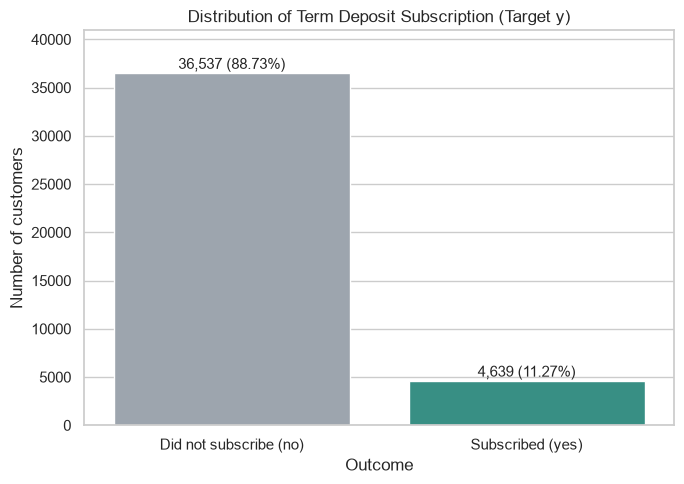

In [14]:
labels = {"no": "Did not subscribe (no)", "yes": "Subscribed (yes)"}
plt.figure(figsize=(7, 5))
ax = sns.barplot(x=[labels[i] for i in target_table.index], y=target_table["count"].values,
                 hue=[labels[i] for i in target_table.index], palette=["#9aa5b1", "#2a9d8f"], legend=False)
for i, (c, p) in enumerate(zip(target_table["count"], target_table["percent"])):
    ax.text(i, c + 400, f"{c:,} ({p:.2f}%)", ha="center", fontsize=11)
plt.title("Distribution of Term Deposit Subscription (Target y)")
plt.xlabel("Outcome")
plt.ylabel("Number of customers")
plt.ylim(0, target_table["count"].max() * 1.12)
save_fig("01_target_distribution")

**Observation:** The bar chart makes the imbalance very visible: the 'no' bar (36,537, 88.73%) is almost eight times taller than the 'yes' bar (4,639, 11.27%). Roughly one call in nine leads to a subscription.

### 2.2 Subscription rate across customer and campaign attributes

**Purpose:** Define a helper that computes the subscription rate (% yes) for each category of a column, saves the table, and draws a bar chart with the overall rate as a dashed reference line.

In [15]:
overall_rate = (df["y"] == "yes").mean() * 100
rate_tables = {}


def rate_by(col, order=None, figsize=(10, 4.8), rotate=0, name=None, ax=None, title=None):
    t = (df.groupby(col)["y"].agg(customers="count", subscribed=lambda s: (s == "yes").sum()))
    t["rate_pct"] = (t["subscribed"] / t["customers"] * 100).round(2)
    t = t.reindex(order) if order else t.sort_values("rate_pct", ascending=False)
    rate_tables[col] = t
    own = ax is None
    if own:
        plt.figure(figsize=figsize)
        ax = plt.gca()
    bars = ax.bar(t.index.astype(str), t["rate_pct"], color="#2a9d8f", label="Subscription rate")
    ax.bar_label(bars, fmt="%.1f", fontsize=8)
    ax.axhline(overall_rate, color="crimson", ls="--", lw=1.5, label=f"Overall rate ({overall_rate:.1f}%)")
    ax.set_title(title or f"Subscription Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Subscription rate (% yes)")
    ax.tick_params(axis="x", rotation=rotate)
    ax.set_ylim(0, t["rate_pct"].max() * 1.4)
    ax.legend(loc="upper right")
    if own:
        save_fig(name)
    return t

**Observation:** The helper is defined; it returns a table of customers, subscribers and subscription rate for each category and draws the chart with the overall rate of 11.27% as a red dashed reference line.

**Purpose:** Subscription rate by job type.

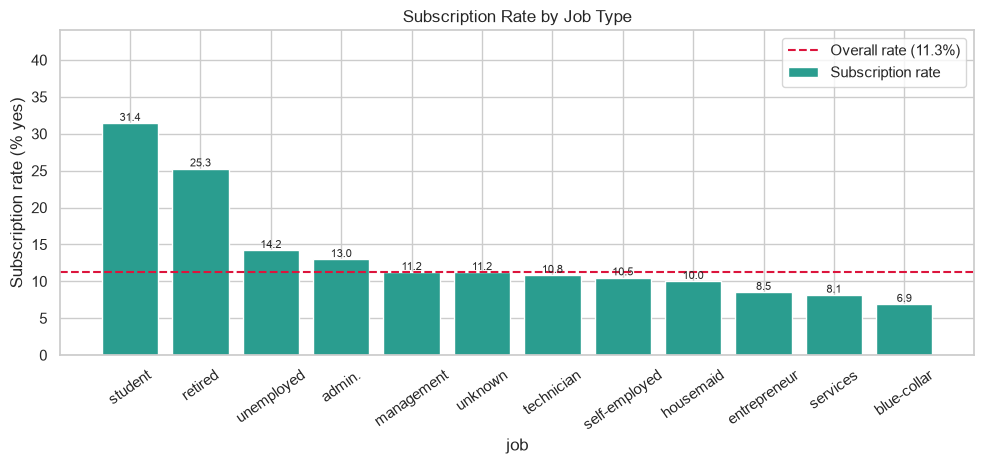

,customers,subscribed,rate_pct
job,,,
student,875,275,31.43
retired,1718,434,25.26
unemployed,1014,144,14.20
admin.,10419,1351,12.97
management,2924,328,11.22
unknown,330,37,11.21
technician,6739,730,10.83
self-employed,1421,149,10.49
housemaid,1060,106,10.00


In [16]:
rate_by("job", rotate=35, name="02_rate_by_job", title="Subscription Rate by Job Type")

**Observation:** **Students (31.43%) and retired customers (25.26%)** subscribe at two to three times the overall rate of 11.27%, followed by unemployed customers (14.20%). **Blue-collar workers have the lowest rate (6.90%)** even though they are the second largest group (9,253 customers), and services (8.14%) and entrepreneurs (8.52%) are also below average. Admin. is the largest group (10,419) with a near-average rate of 12.97%.

**Purpose:** Subscription rate by the month of last contact, in calendar order.

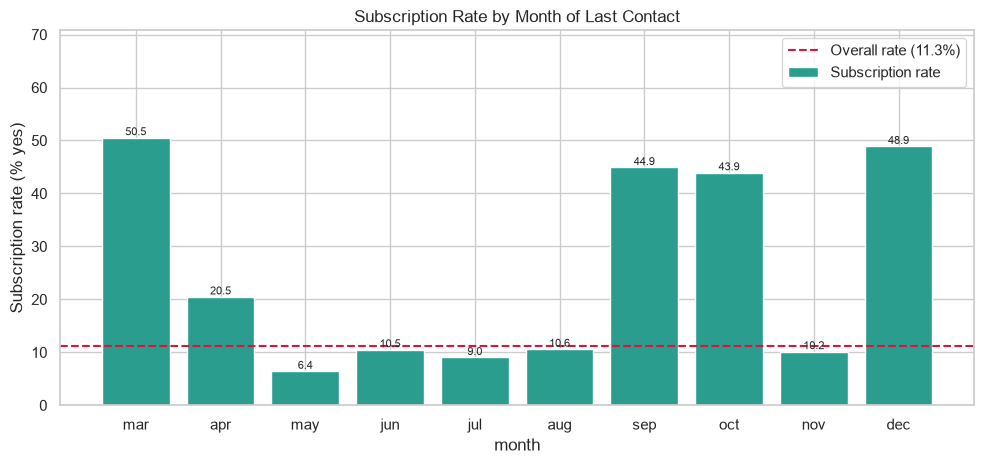

,customers,subscribed,rate_pct
month,,,
mar,546,276,50.55
apr,2631,539,20.49
may,13767,886,6.44
jun,5318,559,10.51
jul,7169,648,9.04
aug,6176,655,10.61
sep,570,256,44.91
oct,717,315,43.93
nov,4100,416,10.15


In [17]:
months = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
rate_by("month", order=months, name="03_rate_by_month", title="Subscription Rate by Month of Last Contact")

**Observation:** The month effect is very strong. **May had the most calls (13,767) but the lowest rate (6.44%)**, while the quiet months had very high rates: **March 50.55%, December 48.90%, September 44.91% and October 43.93%**, each with fewer than 720 calls. This suggests that mass calling in busy months reaches many uninterested customers, while the few calls in quiet months are much more successful (possibly also because of the economic conditions at those times).

**Purpose:** Subscription rate by contact type and by the outcome of the previous campaign, side by side.

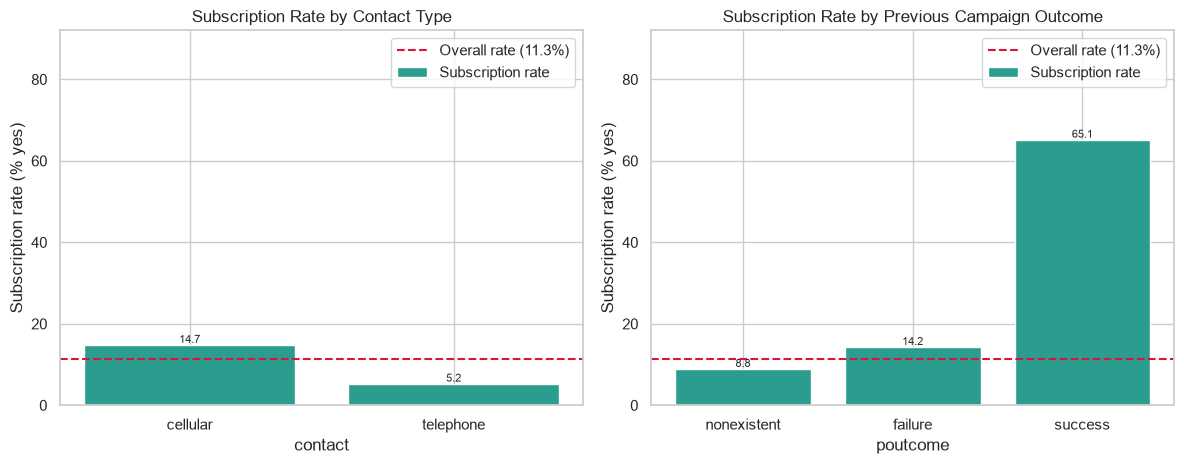

customers  subscribed  rate_pct
contact  cellular         26135        3852     14.74
         telephone        15041         787      5.23
poutcome nonexistent      35551        3140      8.83
         failure           4252         605     14.23
         success           1373         894     65.11

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
rate_by("contact", ax=axes[0], title="Subscription Rate by Contact Type")
rate_by("poutcome", order=["nonexistent", "failure", "success"], ax=axes[1],
        title="Subscription Rate by Previous Campaign Outcome")
axes[0].set_ylim(0, 92)
axes[1].set_ylim(0, 92)
save_fig("04_rate_by_contact_poutcome")
pd.concat({c: rate_tables[c] for c in ["contact", "poutcome"]})

**Observation:** Customers contacted on a **cellular phone subscribed at 14.74%**, almost three times the **5.23% for landline telephone**. The previous campaign outcome is the strongest category in the EDA: customers who said yes last time (**poutcome = success**) subscribed at **65.11%**, against 14.23% after a previous failure and 8.83% for customers never contacted before.

**Purpose:** Subscription rate by education level.

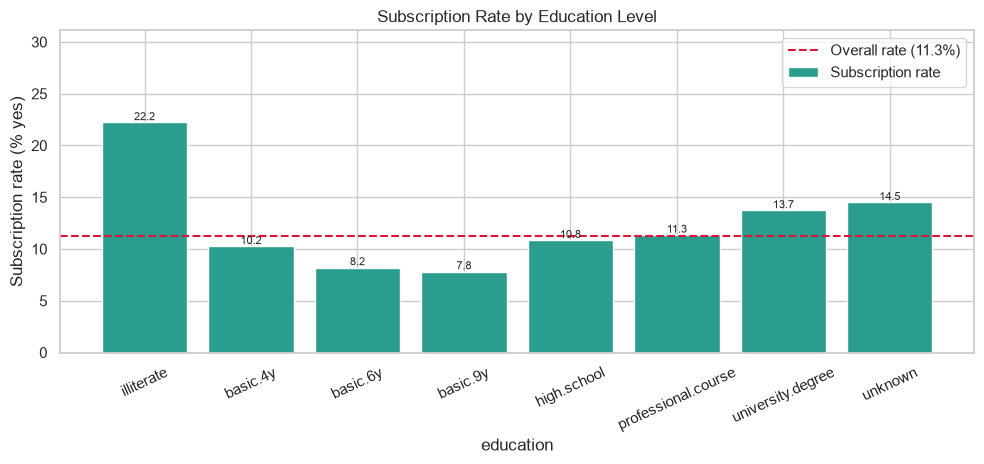

,customers,subscribed,rate_pct
education,,,
illiterate,18,4,22.22
basic.4y,4176,428,10.25
basic.6y,2291,188,8.21
basic.9y,6045,473,7.82
high.school,9512,1031,10.84
professional.course,5240,595,11.35
university.degree,12164,1669,13.72
unknown,1730,251,14.51


In [19]:
edu_order = ["illiterate", "basic.4y", "basic.6y", "basic.9y", "high.school",
             "professional.course", "university.degree", "unknown"]
rate_by("education", order=edu_order, rotate=25, name="05_rate_by_education",
        title="Subscription Rate by Education Level")

**Observation:** Education has a smaller effect than job or month. University graduates subscribe at 13.72% and professional course holders at 11.35%, while basic.9y (7.82%) and basic.6y (8.21%) are the lowest. Illiterate customers show 22.22%, but that is only 4 out of 18 people, so it is not reliable. The 'unknown' education group (14.51%) is above average, another sign that 'unknown' should be kept as its own category.

**Purpose:** Save all subscription rate tables into one CSV for the report.

In [20]:
rates_long = pd.concat(rate_tables, names=["attribute", "category"])
rates_long.to_csv(RES_DIR / "subscription_rates_by_attribute.csv")
print("Overall subscription rate:", round(overall_rate, 2), "%")
print(rates_long.shape)

Overall subscription rate: 11.27 %
(35, 3)


**Observation:** All 35 category rates (from the five attributes) are saved to `results/subscription_rates_by_attribute.csv`, and the overall subscription rate is confirmed as 11.27%.

### 2.3 Numerical variables versus the outcome

**Purpose:** Box plots of age, campaign (number of calls in this campaign), euribor3m (3 month interest rate) and nr.employed (number of employees, an economic indicator) for subscribers and non-subscribers. Outlier points are hidden so the boxes are readable; the medians and means are printed below.

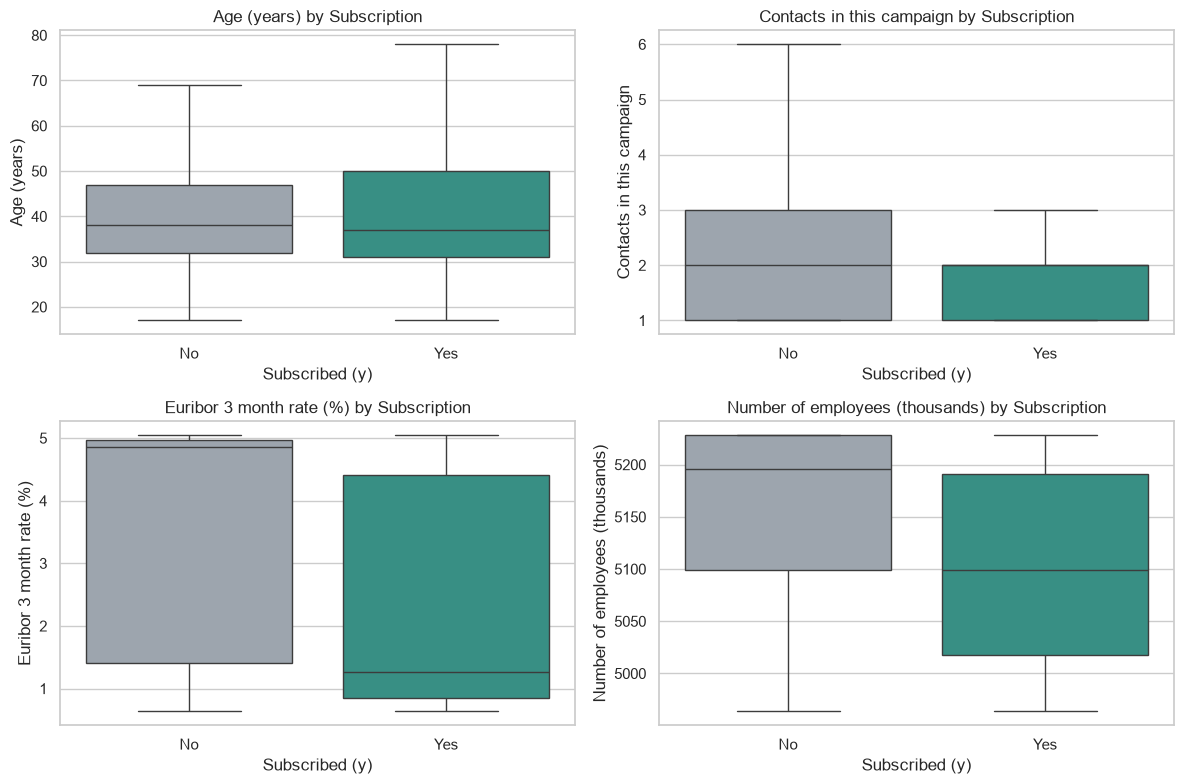

Outcome                  No      Yes
age         median    38.00    37.00
            mean      39.91    40.91
campaign    median     2.00     2.00
            mean       2.63     2.05
euribor3m   median     4.86     1.27
            mean       3.81     2.12
nr.employed median  5195.80  5099.10
            mean    5176.17  5095.12
duration    median   164.00   449.00
            mean     220.87   553.26

In [21]:
num_eda = ["age", "campaign", "euribor3m", "nr.employed"]
nice = {"age": "Age (years)", "campaign": "Contacts in this campaign",
        "euribor3m": "Euribor 3 month rate (%)", "nr.employed": "Number of employees (thousands)"}
eda_df = df.assign(Outcome=df["y"].map({"no": "No", "yes": "Yes"}))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), num_eda):
    sns.boxplot(data=eda_df, x="Outcome", y=col, hue="Outcome", order=["No", "Yes"],
                palette={"No": "#9aa5b1", "Yes": "#2a9d8f"}, showfliers=False, legend=False, ax=ax)
    ax.set_title(f"{nice[col]} by Subscription")
    ax.set_xlabel("Subscribed (y)")
    ax.set_ylabel(nice[col])
save_fig("06_numeric_vs_outcome")
num_by_y = eda_df.groupby("Outcome")[num_eda + ["duration"]].agg(["median", "mean"]).round(2).T
num_by_y.to_csv(RES_DIR / "numeric_by_outcome.csv")
num_by_y

**Observation:** * **age**: almost no difference (median 38 for 'no', 37 for 'yes'), although the 'yes' box is a little wider, which fits the higher rates for students and retired people.
* **campaign**: the median is 2 calls for both, but non-subscribers were called more on average (2.63 vs 2.05), so repeatedly calling the same customer does not seem to help.
* **euribor3m**: a large shift. Subscribers have a **median of 1.27 against 4.86 for non-subscribers**, so customers subscribed much more when interest rates were low.
* **nr.employed**: subscribers are concentrated at lower employment levels (**median 5,099.1 vs 5,195.8**).

The two economic indicators separate the classes much better than the customer's own age or the number of calls.

**Purpose:** For understanding only: compare call `duration` for subscribers and non-subscribers. This variable is **not used in any model** because it is known only after the call.

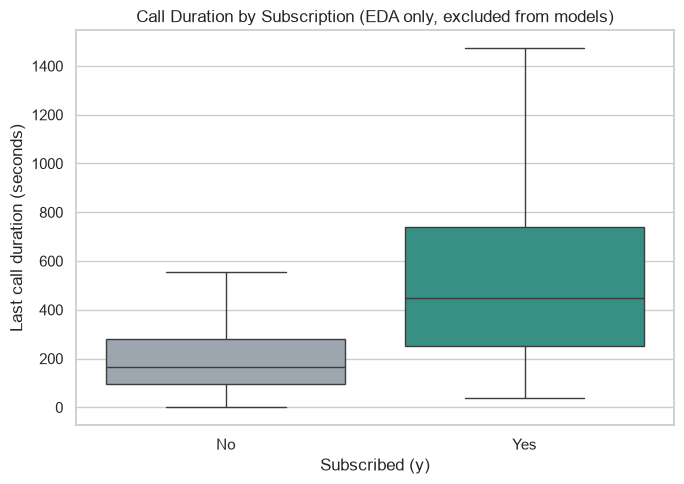

In [22]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=eda_df, x="Outcome", y="duration", hue="Outcome", order=["No", "Yes"],
            palette={"No": "#9aa5b1", "Yes": "#2a9d8f"}, showfliers=False, legend=False)
plt.title("Call Duration by Subscription (EDA only, excluded from models)")
plt.xlabel("Subscribed (y)")
plt.ylabel("Last call duration (seconds)")
save_fig("07_duration_eda_only")

**Observation:** Subscribers had much longer calls (**median 449 seconds against 164**). This shows why duration is so predictive, but it is only known after the call, when the result is already known. It is therefore shown here for understanding only and is not used in any model.

### 2.4 Key observations from the EDA

**Observation:** 1. **The target is strongly imbalanced:** only 4,639 of 41,176 customers (11.27%) subscribed, so accuracy is a weak measure and a model must be judged on how many subscribers it finds (recall) and how many of its 'yes' predictions are right (precision).
2. **Past success is the strongest single signal:** customers whose previous campaign outcome was 'success' subscribed at 65.11%, almost six times the overall rate, while customers never contacted before subscribed at only 8.83%.
3. **Economic conditions matter a lot:** subscribers had a median Euribor 3 month rate of 1.27 against 4.86 for non-subscribers, and lower employment levels (median 5,099.1 vs 5,195.8).
4. **Timing and channel matter:** May had the most calls (13,767) but the lowest rate (6.44%), while March, September, October and December had rates above 43%. Cellular contacts subscribed at 14.74% against 5.23% for landline.
5. **Customer segments differ:** students (31.43%) and retired customers (25.26%) are the most likely to subscribe, and blue-collar workers (6.90%) the least likely.
6. **More calls do not help:** non-subscribers were called 2.63 times on average against 2.05 for subscribers.

## Task 3: Classification Model Development

### 3.1 Models and hyperparameters

All four models use the **same preprocessor, the same training set and the same test set**, so the comparison is fair. The settings are kept simple and explainable rather than heavily tuned:

| Model | Settings | Why |
|---|---|---|
| Logistic Regression | `max_iter=1000`, `class_weight="balanced"` | Simple linear baseline. `max_iter=1000` lets the solver converge on about 60 columns. `class_weight="balanced"` gives the rare "yes" class more weight so the model does not just predict "no" for everyone. |
| Decision Tree | `max_depth=6`, `class_weight="balanced"` | Easy to explain as rules. Depth 6 limits overfitting (a full-depth tree would memorise the training data). Balanced weights for the same reason as above. |
| K-Nearest Neighbours | `n_neighbors=15` | Predicts from the 15 most similar customers. 15 neighbours smooths out noise compared with very small k. **KNN has no `class_weight` option**, so it is trained on the imbalanced data as it is. |
| Random Forest | `n_estimators=300`, `min_samples_leaf=5`, `class_weight="balanced"`, `n_jobs=-1` | An ensemble of 300 trees on random subsets, usually stronger than one tree. `min_samples_leaf=5` stops leaves from fitting single customers. `n_jobs=-1` uses all CPU cores. |

`random_state=42` is set where the model has randomness (Logistic Regression solver, Decision Tree and Random Forest).

**Purpose:** Define the four model pipelines and a function that trains one pipeline, predicts on the test set, calculates all metrics and the confusion matrix, and stores the results.

In [23]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            n_jobs=-1, random_state=RANDOM_STATE),
}
fitted, probas, cms, rows = {}, {}, {}, []


def evaluate(name, clf):
    pipe = Pipeline([("preprocess", make_preprocessor()), ("model", clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    row = {"Model": name,
           "Accuracy": accuracy_score(y_test, pred),
           "Precision": precision_score(y_test, pred),
           "Recall": recall_score(y_test, pred),
           "F1": f1_score(y_test, pred),
           "ROC_AUC": roc_auc_score(y_test, prob),
           "TN": tn, "FP": fp, "FN": fn, "TP": tp}
    fitted[name], probas[name], cms[name] = pipe, prob, cm
    rows.append(row)
    print(f"{name}: accuracy={row['Accuracy']:.4f} precision={row['Precision']:.4f} "
          f"recall={row['Recall']:.4f} F1={row['F1']:.4f} ROC-AUC={row['ROC_AUC']:.4f}")
    print(pd.DataFrame(cm, index=["Actual no", "Actual yes"], columns=["Pred no", "Pred yes"]))
    return row

**Observation:** The four model pipelines and the shared evaluation function are defined. Each model gets its own copy of the same preprocessor, fit on the training data only, and results are added to one common list so the comparison table can be built at the end.

### 3.2 Logistic Regression

**Purpose:** Train and evaluate Logistic Regression.

In [24]:
_ = evaluate("Logistic Regression", models["Logistic Regression"])

Logistic Regression: accuracy=0.8303 precision=0.3591 recall=0.6455 F1=0.4615 ROC-AUC=0.8002
            Pred no  Pred yes
Actual no      6239      1069
Actual yes      329       599


**Observation:** Logistic Regression: **accuracy 0.8303, precision 0.3591, recall 0.6455, F1 0.4615, ROC-AUC 0.8002.** It finds 599 of the 928 subscribers (the highest recall of the four) but also flags 1,069 non-subscribers as 'yes'. Because of `class_weight="balanced"` it is willing to predict 'yes' often, which raises recall but lowers precision: only about 36% of its 'yes' predictions are real subscribers.

### 3.3 Decision Tree

**Purpose:** Train and evaluate the Decision Tree.

In [25]:
_ = evaluate("Decision Tree", models["Decision Tree"])

Decision Tree: accuracy=0.8517 precision=0.3990 recall=0.6239 F1=0.4868 ROC-AUC=0.7948


            Pred no  Pred yes
Actual no      6436       872
Actual yes      349       579


**Observation:** Decision Tree (depth 6): **accuracy 0.8517, precision 0.3990, recall 0.6239, F1 0.4868, ROC-AUC 0.7948.** Compared with Logistic Regression it makes fewer false alarms (872 vs 1,069) but misses slightly more subscribers (349 vs 329). Its ROC-AUC is a little lower because a depth 6 tree only produces a limited number of distinct probability values.

### 3.4 K-Nearest Neighbours

**Purpose:** Train and evaluate KNN.

In [26]:
_ = evaluate("KNN", models["KNN"])

KNN: accuracy=0.8980 precision=0.6106 recall=0.2619 F1=0.3665 ROC-AUC=0.7728
            Pred no  Pred yes
Actual no      7153       155
Actual yes      685       243


**Observation:** KNN (k = 15): **accuracy 0.8980 (the highest) but recall only 0.2619**, precision 0.6106, F1 0.3665 and ROC-AUC 0.7728 (the lowest). It catches only 243 of the 928 subscribers and misses 685. Because KNN cannot use class weights, most of the 15 neighbours of any customer are non-subscribers, so it mostly predicts 'no'. This is a clear example of why high accuracy is misleading on imbalanced data.

### 3.5 Random Forest

**Purpose:** Train and evaluate the Random Forest.

In [27]:
_ = evaluate("Random Forest", models["Random Forest"])

Random Forest: accuracy=0.8571 precision=0.4129 recall=0.6358 F1=0.5006 ROC-AUC=0.8080
            Pred no  Pred yes
Actual no      6469       839
Actual yes      338       590


**Observation:** Random Forest: **accuracy 0.8571, precision 0.4129, recall 0.6358, F1 0.5006, ROC-AUC 0.8080.** It finds 590 of the 928 subscribers (only 9 fewer than Logistic Regression) while making 839 false alarms (230 fewer than Logistic Regression). It has the best F1 and the best ROC-AUC of the four models.

## Task 4: Model Performance Comparison and Visualisation

### 4.1 Final comparison table

**Purpose:** Combine the four result rows into one comparison table, add how many of the actual subscribers each model catches and how many calls it needs per subscriber found, and save the table.

In [28]:
comparison = pd.DataFrame(rows).set_index("Model")
comparison["Subscribers_caught"] = comparison["TP"].astype(str) + " / " + str(int(y_test.sum()))
comparison["Calls_per_subscriber"] = ((comparison["TP"] + comparison["FP"]) / comparison["TP"]).round(2)
metric_cols = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
comparison[metric_cols] = comparison[metric_cols].round(4)
comparison.to_csv(RES_DIR / "model_comparison.csv")
comparison

,Accuracy,Precision,Recall,F1,ROC_AUC,TN,FP,FN,TP,Subscribers_caught,Calls_per_subscriber
Model,,,,,,,,,,,
Logistic Regression,0.8303,0.3591,0.6455,0.4615,0.8002,6239,1069,329,599,599 / 928,2.78
Decision Tree,0.8517,0.3990,0.6239,0.4868,0.7948,6436,872,349,579,579 / 928,2.51
KNN,0.8980,0.6106,0.2619,0.3665,0.7728,7153,155,685,243,243 / 928,1.64
Random Forest,0.8571,0.4129,0.6358,0.5006,0.8080,6469,839,338,590,590 / 928,2.42


**Observation:** The final table shows a clear trade-off. **KNN has the highest accuracy (0.8980) and precision (0.6106) but finds only 243 of 928 subscribers.** The three balanced models all find about 62% to 65% of subscribers. **Random Forest has the best F1 (0.5006) and ROC-AUC (0.8080)**, Logistic Regression the best recall (0.6455). The calls-per-subscriber column shows the cost side: Random Forest needs 2.42 calls for every subscriber it finds, against 2.78 for Logistic Regression and 2.51 for the Decision Tree; KNN needs only 1.64 but leaves most subscribers undiscovered. Three of the four accuracies are below the 0.8873 accuracy of always predicting 'no' and KNN is only 0.0107 above it, which again shows that accuracy is not the right measure here.

### 4.2 Grouped bar chart of the evaluation metrics

**Purpose:** Compare accuracy, precision, recall and F1 of the four models in one grouped bar chart.

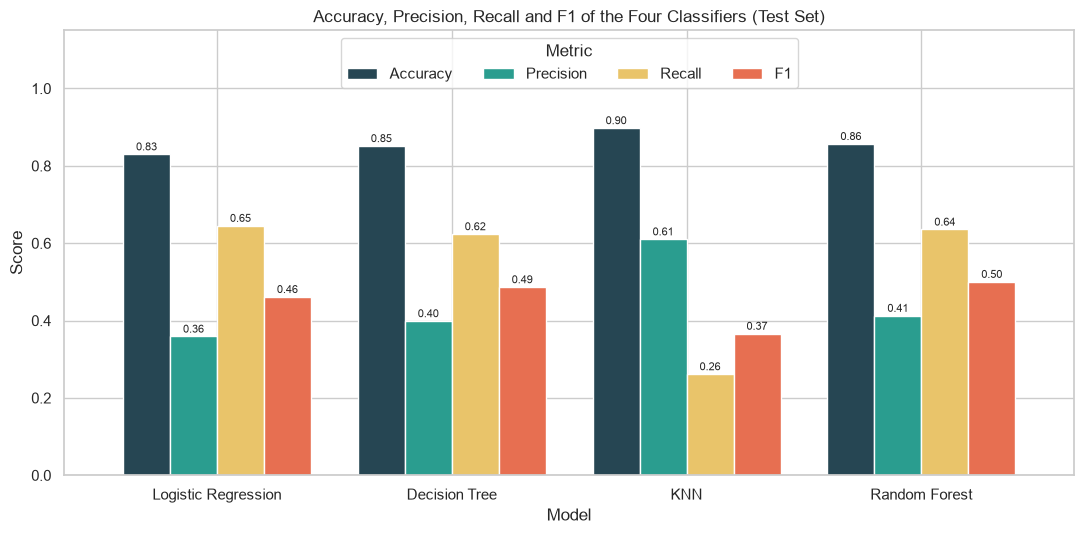

In [29]:
bar_df = comparison[["Accuracy", "Precision", "Recall", "F1"]]
ax = bar_df.plot(kind="bar", figsize=(11, 5.5), width=0.8,
                 color=["#264653", "#2a9d8f", "#e9c46a", "#e76f51"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8, padding=1)
plt.title("Accuracy, Precision, Recall and F1 of the Four Classifiers (Test Set)")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.15)
plt.xticks(rotation=0)
plt.legend(title="Metric", loc="upper center", ncol=4)
save_fig("08_metrics_grouped_bar")

**Observation:** The chart shows that the accuracy bars are all high (0.83 to 0.90) and hardly separate the models, while recall and F1 differ a lot. KNN stands out with the tallest accuracy and precision bars but by far the shortest recall bar (0.26). Logistic Regression, Decision Tree and Random Forest have similar recall (0.62 to 0.65), and Random Forest has the highest precision (0.41) and F1 (0.50) among them.

### 4.3 Confusion matrices

**Purpose:** Plot all four confusion matrices in a 2x2 grid with the same labels, so the error types of each model can be compared directly. TN = correctly predicted non-subscriber, FP = predicted yes but did not subscribe (a wasted call), FN = predicted no but did subscribe (a missed subscriber), TP = correctly found subscriber.

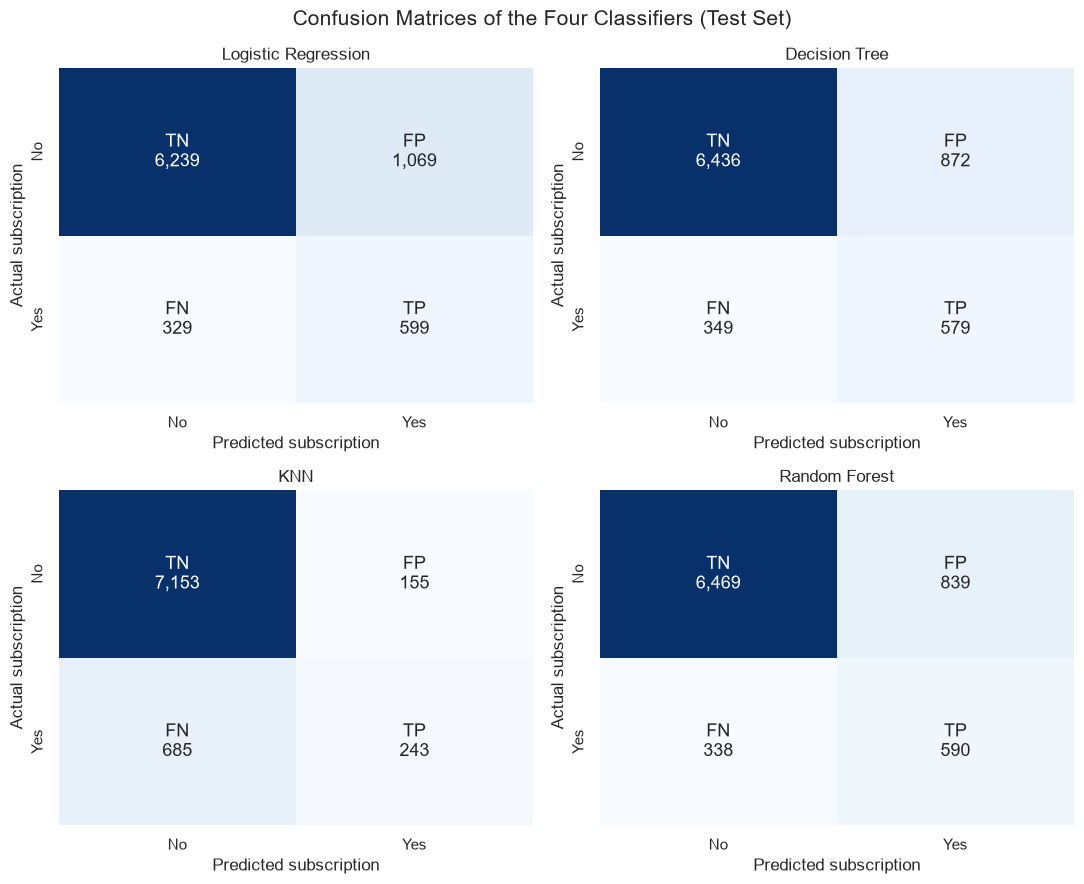

In [30]:
cm_labels = ["No", "Yes"]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, cm) in zip(axes.ravel(), cms.items()):
    annot = np.array([[f"TN\n{cm[0,0]:,}", f"FP\n{cm[0,1]:,}"], [f"FN\n{cm[1,0]:,}", f"TP\n{cm[1,1]:,}"]])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=cm_labels, yticklabels=cm_labels, annot_kws={"size": 13})
    ax.set_title(name)
    ax.set_xlabel("Predicted subscription")
    ax.set_ylabel("Actual subscription")
fig.suptitle("Confusion Matrices of the Four Classifiers (Test Set)", fontsize=15)
save_fig("09_confusion_matrices")
with open(RES_DIR / "confusion_matrices.json", "w") as f:
    json.dump({k: v.tolist() for k, v in cms.items()}, f, indent=2)

**Observation:** * **Logistic Regression:** TN 6,239, FP 1,069, FN 329, TP 599. It misses the fewest subscribers but wastes the most calls.
* **Decision Tree:** TN 6,436, FP 872, FN 349, TP 579. Fewer wasted calls than Logistic Regression, 20 more missed subscribers.
* **KNN:** TN 7,153, FP 155, FN 685, TP 243. Very few wasted calls, but it misses 685 subscribers (74% of them), which is the most expensive kind of error for the bank.
* **Random Forest:** TN 6,469, FP 839, FN 338, TP 590. Close to Logistic Regression on missed subscribers (338 vs 329) while making 230 fewer wasted calls, the best balance of the four.

For all models the false positives outnumber the true positives, because subscribers are rare (11.27%); this is the price of finding most of them.

### 4.4 ROC curves

**Purpose:** Plot the ROC curves of all four models on one chart with their ROC-AUC in the legend. ROC-AUC measures how well each model ranks subscribers above non-subscribers, independent of the 0.5 threshold.

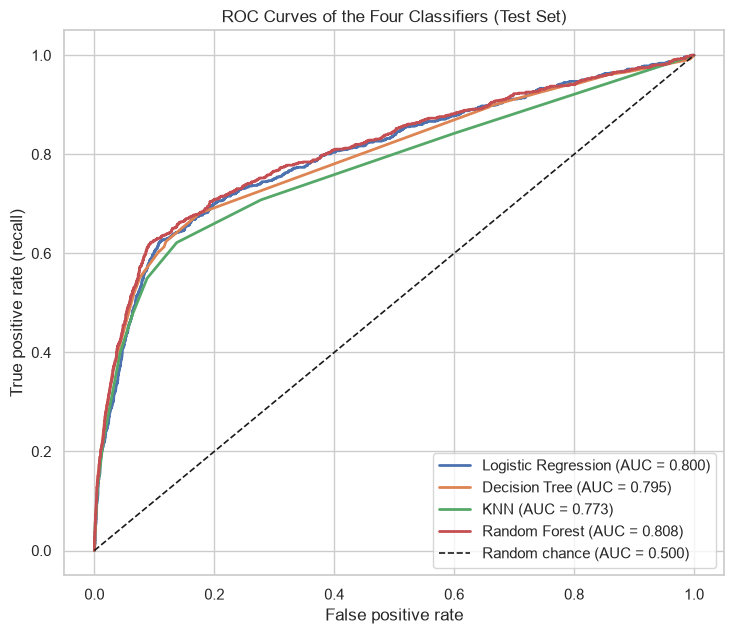

In [31]:
plt.figure(figsize=(7.5, 6.5))
for name, prob in probas.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {comparison.loc[name, 'ROC_AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1.2, label="Random chance (AUC = 0.500)")
plt.title("ROC Curves of the Four Classifiers (Test Set)")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.legend(loc="lower right")
save_fig("10_roc_curves")

**Observation:** All four ROC curves lie well above the random chance diagonal. **Random Forest has the highest AUC (0.808)**, closely followed by Logistic Regression (0.800) and the Decision Tree (0.795), with KNN lowest (0.773). The curves of Random Forest and Logistic Regression are very close, so their ability to rank customers is similar, with Random Forest slightly ahead. KNN's low recall at the 0.5 threshold is partly a threshold problem: its AUC of 0.773 shows its probabilities still contain useful ranking information.

### 4.5 Ability to identify actual subscribers

**Purpose:** Compare how many of the actual subscribers in the test set each model catches (TP) and misses (FN), since finding subscribers is the purpose of the campaign.

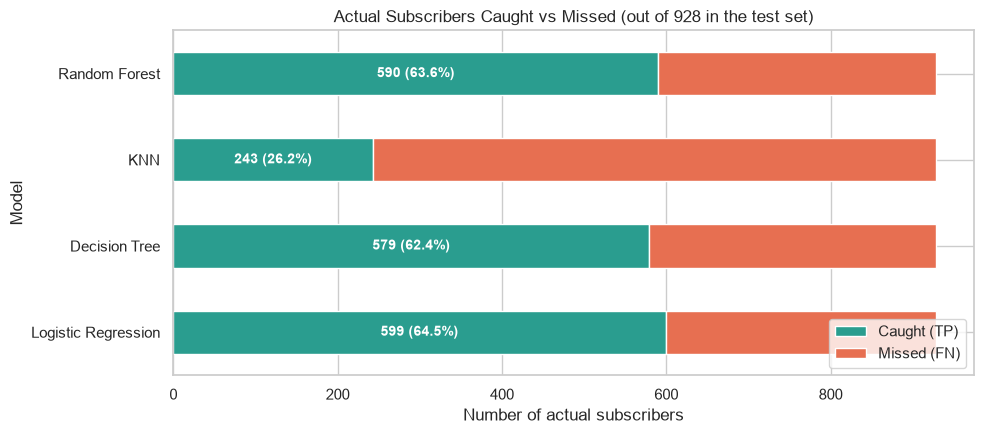

,TP,FN,caught_pct
Model,,,
Logistic Regression,599,329,64.55
Decision Tree,579,349,62.39
KNN,243,685,26.19
Random Forest,590,338,63.58


In [32]:
pos = int(y_test.sum())
caught = comparison[["TP", "FN"]].copy()
caught["caught_pct"] = (caught["TP"] / pos * 100).round(2)
ax = caught[["TP", "FN"]].rename(columns={"TP": "Caught (TP)", "FN": "Missed (FN)"}).plot(
    kind="barh", stacked=True, figsize=(10, 4.5), color=["#2a9d8f", "#e76f51"])
for i, (tp, p) in enumerate(zip(caught["TP"], caught["caught_pct"])):
    ax.text(tp / 2, i, f"{tp} ({p:.1f}%)", va="center", ha="center", color="white", fontsize=10, fontweight="bold")
plt.title(f"Actual Subscribers Caught vs Missed (out of {pos} in the test set)")
plt.xlabel("Number of actual subscribers")
plt.ylabel("Model")
plt.legend(loc="lower right")
save_fig("11_subscribers_caught")
caught.to_csv(RES_DIR / "subscribers_caught.csv")
caught

**Observation:** Out of the 928 actual subscribers in the test set, **Logistic Regression catches 599 (64.55%), Random Forest 590 (63.58%), the Decision Tree 579 (62.39%) and KNN only 243 (26.19%)**. The three balanced models are within 20 subscribers of each other, while KNN misses almost three out of four subscribers.

### 4.6 Choosing the best model

**Purpose:** Rank the models on each metric (1 = best) to see which model is strongest across the threshold-based metrics (precision, recall, F1) and the ranking metric (ROC-AUC). Accuracy is shown but not used alone, because a model that always says 'no' would already reach about 89% accuracy.

In [33]:
print(f"Accuracy of always predicting 'no': {1 - y_test.mean():.4f}")
ranks = comparison[["Precision", "Recall", "F1", "ROC_AUC"]].rank(ascending=False).astype(int)
ranks["Mean_rank"] = ranks.mean(axis=1)
ranks.sort_values("Mean_rank")

Accuracy of always predicting 'no': 0.8873


,Precision,Recall,F1,ROC_AUC,Mean_rank
Model,,,,,
Random Forest,2,2,1,1,1.50
Logistic Regression,4,1,3,2,2.50
Decision Tree,3,3,2,3,2.75
KNN,1,4,4,4,3.25


**Observation:** Always predicting 'no' would give an accuracy of 0.8873, which is higher than three of the four models; this proves accuracy cannot be used to choose the model. On the four metrics that matter, **Random Forest has the best mean rank (1.50)**: first on F1 and ROC-AUC and second on precision and recall. Logistic Regression is second (2.50), the Decision Tree third (2.75) and KNN last (3.25) despite having the best precision.

**Observation:** **Choice of the best model: Random Forest.**

* **Business cost of errors:** a false negative is a customer who would have subscribed but is never called, which means a lost term deposit. A false positive is a call to a customer who says no, which costs a few minutes of an agent's time. Missing a subscriber is the more expensive error, so recall is important, but precision also matters because the call centre has limited capacity.
* **KNN is rejected** even though it has the highest accuracy (0.8980) and precision (0.6106), because it misses 685 of 928 subscribers (recall 0.2619).
* **Logistic Regression vs Random Forest:** Logistic Regression finds 9 more subscribers (599 vs 590), but to do so it makes 230 more wasted calls (1,069 vs 839). Random Forest therefore has higher precision (0.4129 vs 0.3591), higher F1 (0.5006 vs 0.4615) and needs fewer calls per subscriber found (2.42 vs 2.78).
* **Random Forest has the highest ROC-AUC (0.8080)**, which matters because the bank can use the predicted probability to rank customers and choose its own cut-off.

Random Forest gives the best balance between finding subscribers and not wasting calls. Logistic Regression is a close second and would be a reasonable choice if the bank needed a model that is easier to explain.

**Purpose:** Store the name of the chosen model so the gains chart and saved results refer to it.

In [34]:
BEST_MODEL = comparison["ROC_AUC"].idxmax()
print("Best model (highest ROC-AUC, see justification above):", BEST_MODEL)
with open(RES_DIR / "best_model.json", "w") as f:
    json.dump({"best_model": BEST_MODEL, **comparison.loc[BEST_MODEL, metric_cols].to_dict(),
               "test_positives": pos, "baseline_accuracy_all_no": round(float(1 - y_test.mean()), 4)}, f, indent=2)

Best model (highest ROC-AUC, see justification above): Random Forest


**Observation:** The code picks the model with the highest ROC-AUC, which is **Random Forest**, matching the choice argued above. Its metrics are saved to `results/best_model.json`.

### 4.7 Cumulative gains chart for the best model

**Purpose:** Sort the test customers by the best model's predicted probability (highest first) and calculate what percentage of all actual subscribers is reached when the bank calls only the top 10%, 20%, 30% and so on of the list. A random calling order would reach the same percentage of subscribers as of customers (the diagonal).

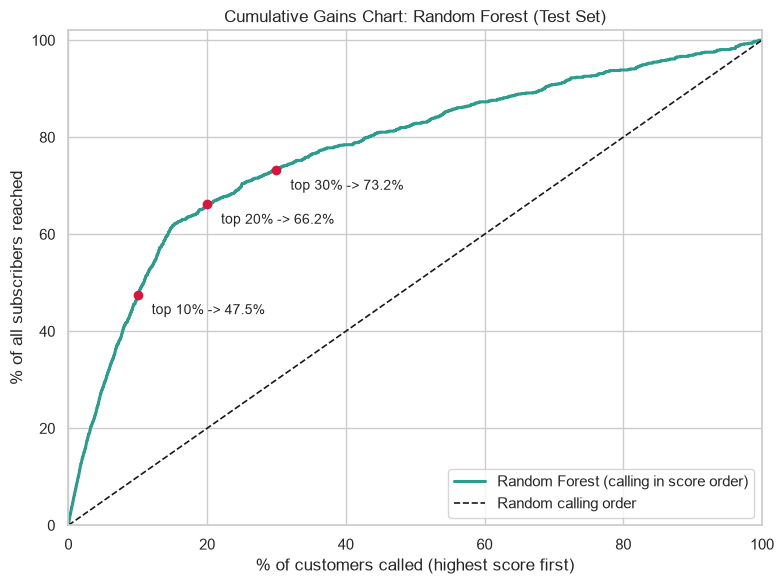

,top_pct_called,customers_called,subscribers_reached,pct_subscribers_reached,lift
0,10,824,441,47.52,4.75
1,20,1647,614,66.16,3.31
2,30,2471,679,73.17,2.44
3,40,3294,728,78.45,1.96
4,50,4118,769,82.87,1.66
5,60,4942,810,87.28,1.45
6,70,5765,843,90.84,1.30
7,80,6589,871,93.86,1.17
8,90,7412,899,96.88,1.08
9,100,8236,928,100.00,1.00


In [35]:
order = np.argsort(-probas[BEST_MODEL])
y_sorted = y_test.to_numpy()[order]
pct_customers = np.arange(1, len(y_sorted) + 1) / len(y_sorted) * 100
pct_subscribers = np.cumsum(y_sorted) / y_sorted.sum() * 100

gains = pd.DataFrame({"top_pct_called": range(10, 101, 10)})
gains["customers_called"] = (gains["top_pct_called"] / 100 * len(y_sorted)).round().astype(int)
gains["subscribers_reached"] = [int(y_sorted[:n].sum()) for n in gains["customers_called"]]
gains["pct_subscribers_reached"] = (gains["subscribers_reached"] / y_sorted.sum() * 100).round(2)
gains["lift"] = (gains["pct_subscribers_reached"] / gains["top_pct_called"]).round(2)
gains.to_csv(RES_DIR / "cumulative_gains.csv", index=False)

plt.figure(figsize=(8, 6))
plt.plot(pct_customers, pct_subscribers, color="#2a9d8f", lw=2.2, label=f"{BEST_MODEL} (calling in score order)")
plt.plot([0, 100], [0, 100], "k--", lw=1.2, label="Random calling order")
for _, r in gains[gains["top_pct_called"].isin([10, 20, 30])].iterrows():
    plt.scatter(r["top_pct_called"], r["pct_subscribers_reached"], color="crimson", zorder=3)
    plt.annotate(f"top {int(r['top_pct_called'])}% -> {r['pct_subscribers_reached']:.1f}%",
                 (r["top_pct_called"], r["pct_subscribers_reached"]),
                 textcoords="offset points", xytext=(10, -14), fontsize=10)
plt.title(f"Cumulative Gains Chart: {BEST_MODEL} (Test Set)")
plt.xlabel("% of customers called (highest score first)")
plt.ylabel("% of all subscribers reached")
plt.xlim(0, 100)
plt.ylim(0, 102)
plt.legend(loc="lower right")
save_fig("12_cumulative_gains")
gains

**Observation:** Calling customers in the order of Random Forest's score is far better than calling at random:

* Calling the **top 10% (824 customers) reaches 441 subscribers, 47.52% of all subscribers**, a lift of 4.75 over random calling.
* The **top 20% reaches 66.16%** (lift 3.31) and the **top 30% reaches 73.17%** (lift 2.44).
* Calling half of the list reaches 82.87% of subscribers.

The curve is steep at the start and then flattens: after about the top 30%, each extra block of calls finds fewer new subscribers. This tells the bank where most of the value lies.

### 4.8 Random Forest feature importance

**Purpose:** Show the 15 most important encoded features of the Random Forest (mean decrease in impurity). This tells which attributes the forest relies on most to separate subscribers from non-subscribers.

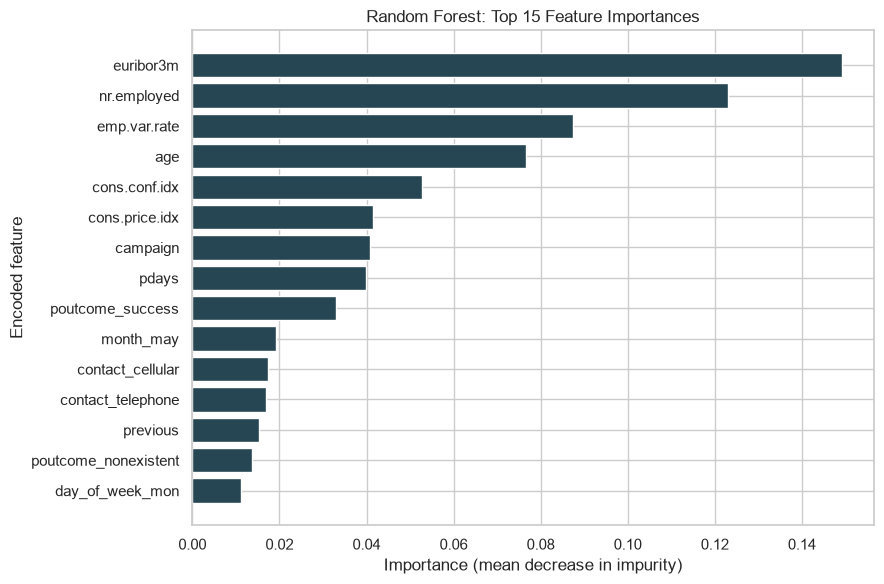

euribor3m               0.1491
nr.employed             0.1231
emp.var.rate            0.0874
age                     0.0766
cons.conf.idx           0.0527
cons.price.idx          0.0415
campaign                0.0409
pdays                   0.0399
poutcome_success        0.0329
month_may               0.0193
contact_cellular        0.0174
contact_telephone       0.0169
previous                0.0152
poutcome_nonexistent    0.0136
day_of_week_mon         0.0111
dtype: float64

In [36]:
rf_pipe = fitted["Random Forest"]
names = rf_pipe.named_steps["preprocess"].get_feature_names_out()
names = [n.split("__", 1)[1] for n in names]
importance = (pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=names)
              .sort_values(ascending=False))
top15 = importance.head(15).round(4)
top15.rename("importance").to_csv(RES_DIR / "rf_feature_importance_top15.csv", index_label="feature")

plt.figure(figsize=(9, 6))
plt.barh(top15.index[::-1], top15.values[::-1], color="#264653")
plt.title("Random Forest: Top 15 Feature Importances")
plt.xlabel("Importance (mean decrease in impurity)")
plt.ylabel("Encoded feature")
save_fig("13_rf_feature_importance")
top15

**Observation:** The **top three features are all economic indicators: euribor3m (0.1491), nr.employed (0.1231) and emp.var.rate (0.0874)**, followed by age (0.0766), cons.conf.idx (0.0527) and cons.price.idx (0.0415). Campaign (0.0409), pdays (0.0399) and poutcome_success (0.0329) are the most useful campaign features, and month_may and the contact type also appear in the top 15. This agrees with the EDA, where Euribor, employment, previous success, month and contact type showed the largest differences. One caution: impurity-based importance tends to favour continuous features with many split points, so binary columns such as poutcome_success may be under-rated compared with their strong effect in the EDA (65.11% subscription rate).

## Task 5: Interpretation and Business Recommendations

### 5.1 Best model and why it suits the bank

**Observation:** **Random Forest** is the best model for the bank's problem. It has the best F1-score (0.5006) and ROC-AUC (0.8080) of the four models, finds 590 of the 928 test subscribers (recall 0.6358), and does this with fewer wasted calls (839) than Logistic Regression (1,069) or the Decision Tree (872).

It suits the bank because:

* It handles the class imbalance through `class_weight="balanced"`, so it does not ignore the rare subscribers the way KNN does.
* It uses only information available **before** the call (duration is excluded), so it can actually be used to plan a campaign.
* Its probabilities rank customers well: calling the top 10% of its list reaches 47.52% of all subscribers, and the top 30% reaches 73.17%.
* It captures non-linear effects and interactions (for example economic conditions combined with month and previous outcome) without manual feature engineering, and its feature importances agree with the EDA.

### 5.2 Business recommendations

**Observation:** 1. **Call customers in score order instead of randomly.** Score every customer with the Random Forest and call from the top of the list. On the test set, the top 20% of the list contained 66.16% of all subscribers, so the bank could reach about two thirds of potential subscribers with one fifth of the calls, or set the cut-off based on how many agents are available.
2. **Prioritise customers who subscribed in a previous campaign and use cellular numbers.** Previous 'success' customers subscribed at 65.11% and cellular contacts at 14.74% against 5.23% for landlines.
3. **Do not keep calling the same customer and avoid concentrating calls in one month.** Non-subscribers received more calls on average (2.63 vs 2.05), and May had 13,767 calls but only a 6.44% success rate, compared with over 43% in March, September, October and December. Spreading calls across the year and capping repeat calls would save effort.
4. **Time campaigns with economic conditions.** The most important features were Euribor, employment and the employment variation rate; subscriptions were much higher when the Euribor rate was low (median 1.27 for subscribers). Campaign size can be increased when these indicators are favourable.
5. **Focus on segments with higher rates** such as students (31.43%) and retired customers (25.26%), while using the model score rather than job alone to decide who to call.

### 5.3 Limitations

**Observation:** 1. **Data from 2008 to 2010 economic conditions.** The data covers one Portuguese bank during the financial crisis, and the most important features are economic indicators. If interest rates and employment today are very different, the model's patterns may not hold and it would need retraining on recent data.
2. **`duration` excluded.** This was the right choice for a realistic pre-call model, but it removes the single strongest signal (median call length 449 seconds for subscribers vs 164), so the best F1 here is only 0.5006. A model with duration would score much higher but could not be used before calling.
3. **Default 0.5 threshold.** All metrics use a 0.5 probability cut-off. A different threshold would change precision and recall a lot (KNN's recall of 0.2619 is mainly a threshold effect). The bank should choose the threshold based on call centre capacity and the value of a deposit; the gains chart helps with this.
4. **Limited tuning and a single split.** Hyperparameters were set by reasoning, not by cross-validated search, and results come from one 80:20 split. Tuning could improve every model a little and might change the small gap between Random Forest and Logistic Regression.
5. **'unknown' values.** 20.87% of `default` values are 'unknown'. Treating them as a category works, but the real values behind them are not known, which adds noise.

## Conclusion

**Observation:** * The Bank Marketing data (41,176 rows after removing 12 duplicates) is strongly imbalanced, with only 11.27% subscribers, so accuracy alone is misleading: always predicting 'no' would score 0.8873.
* The EDA showed that previous campaign success (65.11% subscription), low Euribor rates, cellular contact, quiet months (March, September, October, December) and students or retired customers are linked with subscribing.
* Four classifiers were trained on the same leak-free pipeline and split, with `duration` excluded. **Random Forest gave the best balance: F1 0.5006, ROC-AUC 0.8080, recall 0.6358 and precision 0.4129**, catching 590 of 928 test subscribers with 839 wasted calls. Logistic Regression was a close second (F1 0.4615, ROC-AUC 0.8002), the Decision Tree third, and KNN had the highest accuracy (0.8980) but missed 74% of subscribers.
* Calling customers in Random Forest score order reaches 47.52% of subscribers in the top 10% of calls and 73.17% in the top 30%, which makes the model directly useful for planning campaigns.
* The main limitations are the 2008 to 2010 economic context, the exclusion of call duration, the default 0.5 threshold and the limited tuning.

## Attribution

Code structure drafted with AI assistance (Claude); executed, verified and interpreted by Nikhil Kotte. Dataset sources: Bank Marketing (with social/economic context), UCI Machine Learning Repository, `bank-additional-full.csv`; S. Moro, P. Cortez and P. Rita, "A Data-Driven Approach to Predict the Success of Bank Telemarketing", Decision Support Systems, 2014, doi:10.1016/j.dss.2014.03.001.